# Мультимодальные маркеры лжи: исследовательский анализ

Результаты работы пайплайна загружаются ноутбуком из директорий `data/processed/` и `outputs/`. Запись девяти сессий была сделана 30.09, а s14 записали 07.10, при этом в него включён ещё и ФПГ пальца.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from lie_detector.config import sessions, processed_dir, REPO_ROOT
OUT = REPO_ROOT / 'outputs'
sns.set_theme(style='whitegrid')
df = pd.read_csv(OUT / 'dataset.csv')
load = lambda sid, name: json.loads((processed_dir(sid) / name).read_text(encoding='utf-8'))
print(json.loads((OUT / 'summary.json').read_text()))
df[df.y_self.notna()].groupby('sid').y_self.agg(answers='count', lies='sum')

{'self': {'answers': 638, 'lies': 118, 'subjects': 10}, 'scenario': {'answers': 514, 'lies': 338, 'subjects': 10}}


,answers,lies
sid,,
s01,59,20.0
s02,63,17.0
s04,60,10.0
s05,61,16.0
s06,78,6.0
s07,69,10.0
s08,56,6.0
s09,67,8.0
s10,58,14.0


## 1. Синхронизация видео ↔ БиоРадио

In [2]:
sync = pd.DataFrame({sid: {'day': s.source, **load(sid, 'sync.json')} for sid, s in sessions().items()}).T
sync['offset_minus_button_s'] = np.where(sync.day == 'day1', sync.offset.astype(float) - sync.coarse_offset.astype(float), np.nan)
sync.drop(columns='offset_before_pulse')

,day,offset,method,coarse_offset,score,video_duration,pulse_correction_s,rppg_pulse_lag_s,rppg_pulse_lag_r,offset_minus_button_s
s01,day1,192.44,video_breathing_xcorr+rppg_pulse,191.552,0.896444,731.584,-0.0,0.2,0.471554,0.888
s02,day1,54.12,video_breathing_xcorr+rppg_pulse,53.104,0.37971,864.064,1.8,0.2,0.503017,1.016
s04,day1,20.88,video_breathing_xcorr+rppg_pulse,22.432,0.375496,930.304,-0.28,0.2,0.357109,-1.552
s05,day1,41.76,video_breathing_xcorr,40.392,0.470617,889.024,NaN,0.16,0.115311,1.368
s06,day1,27.16,video_breathing_xcorr+rppg_pulse,25.352,0.790048,1121.344,-0.04,0.2,0.396865,1.808
s07,day1,137.64,video_breathing_xcorr+rppg_pulse,137.296,0.257878,909.184,1.32,0.2,0.514371,0.344
s08,day1,100.12,video_breathing_xcorr+rppg_pulse,100.472,0.839584,727.264,-0.16,0.2,0.636009,-0.352
s09,day1,133.4,video_breathing_xcorr,134.104,0.21232,1269.184,NaN,2.36,0.242485,-0.704
s10,day1,41.2,video_breathing_xcorr+rppg_pulse,40.168,0.782872,637.984,0.08,0.2,0.550485,1.032
s14,day2,46.96,video_breathing_xcorr+rppg_pulse,45.76,0.449987,997.024,1.2,0.2,0.601609,NaN


## 2. ЭКГ: качество и реакция на интервью

In [3]:
rows = []
for sid in sessions():
    b = load(sid, 'bio_summary.json')
    r = {'sid': sid, **{f'q_{k}': v for k, v in b['ecg_quality'].items()}, 'rest_s': b['pre_rest_s']}
    for ph in ('pre', 'interview'):
        r.update({f'{k}_{ph}': (b[f'hrv_{ph}'] or {}).get(k) for k in ('HR_mean', 'RMSSD', 'SDNN', 'SI_Baevsky', 'LF_HF')})
    rows.append(r)
pd.DataFrame(rows).set_index('sid').round(2)

,q_n_beats,q_frac_physiological,q_frac_jumps_gt20pct,q_hr_median_bpm,rest_s,HR_mean_pre,RMSSD_pre,SDNN_pre,SI_Baevsky_pre,LF_HF_pre,HR_mean_interview,RMSSD_interview,SDNN_interview,SI_Baevsky_interview,LF_HF_interview
sid,,,,,,,,,,,,,,,
s01,1779,1.00,0.01,115.16,192.44,109.32,32.54,67.24,108.86,5.86,116.34,25.10,59.89,115.89,6.06
s02,1772,1.00,0.00,108.89,54.12,NaN,NaN,NaN,NaN,NaN,110.31,26.29,65.94,82.34,5.23
s04,1669,1.00,0.01,107.72,20.88,NaN,NaN,NaN,NaN,NaN,105.55,36.05,79.46,72.85,6.12
s05,1305,1.00,0.02,82.76,41.76,NaN,NaN,NaN,NaN,NaN,83.33,47.71,64.99,53.28,1.29
s06,1962,1.00,0.00,98.68,27.16,NaN,NaN,NaN,NaN,NaN,98.78,30.34,55.13,76.01,2.43
s07,1751,1.00,0.00,100.17,137.64,102.41,10.39,27.72,318.25,4.83,100.01,17.66,37.25,147.94,3.03
s08,1321,0.99,0.01,93.60,100.12,92.77,25.48,41.03,200.50,6.39,94.08,15.70,47.31,108.53,14.62
s09,1743,1.00,0.02,70.59,133.40,74.47,62.79,86.67,44.48,1.34,72.94,62.97,112.58,16.09,2.05
s10,1058,1.00,0.00,87.46,41.20,NaN,NaN,NaN,NaN,NaN,88.21,25.43,65.84,59.64,6.17


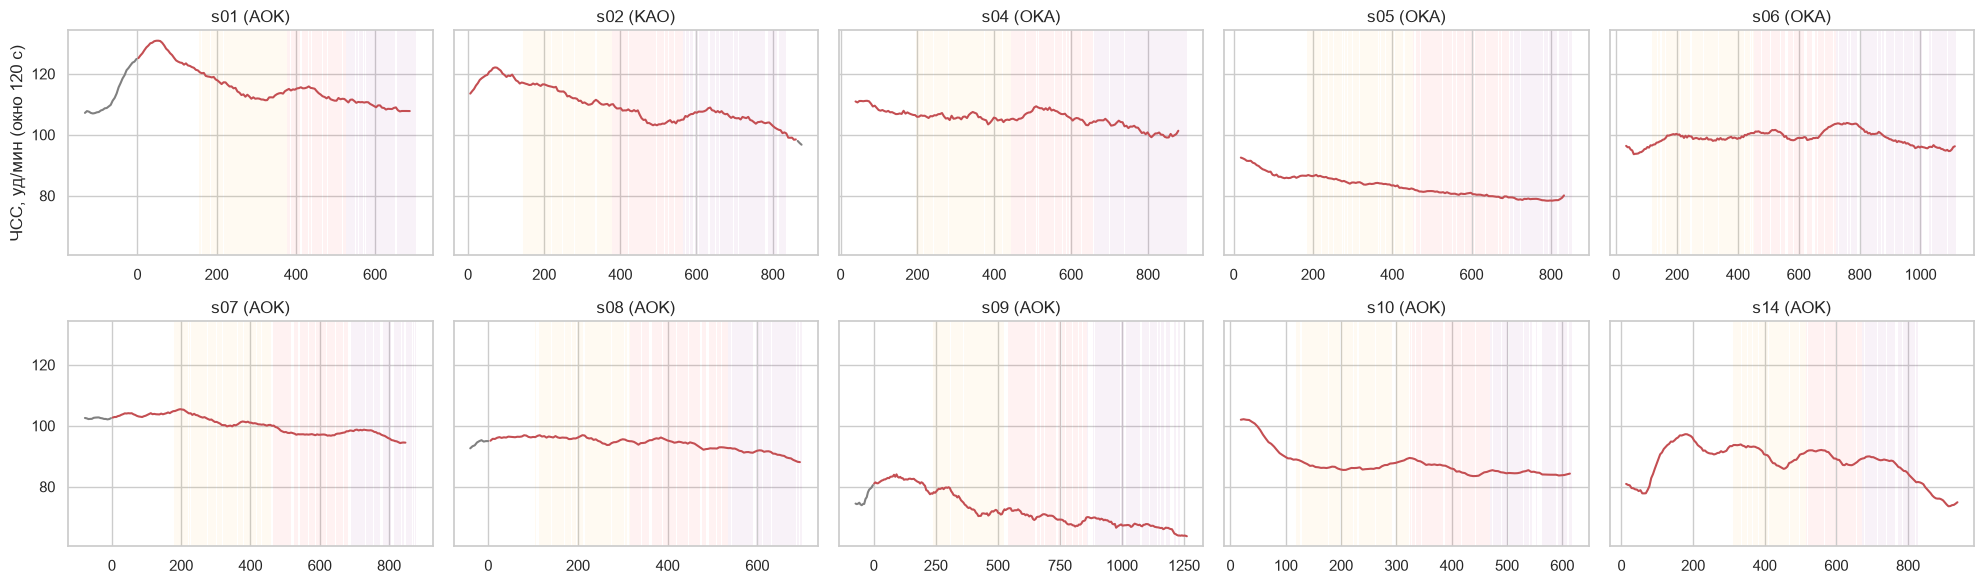

In [4]:
colors = {'alcohol': 'orange', 'conflict': 'red', 'deception': 'purple'}
def topics(ax, sid):
    for u in load(sid, 'dialog.json'):
        if u['topic'] in colors:
            ax.axvspan(u['start'], u['end'], color=colors[u['topic']], alpha=.05, lw=0)
fig, axes = plt.subplots(2, 5, figsize=(20, 6), sharey=True)
for ax, sid in zip(axes.ravel(), sessions()):
    h = pd.read_csv(processed_dir(sid) / 'hrv_ecg.csv')
    for ph, c in (('pre', 'grey'), ('interview', 'C3'), ('post', 'grey')):
        ax.plot(h.t_video[h.phase == ph], h.HR_mean[h.phase == ph], color=c)
    topics(ax, sid)
    ax.set_title(f'{sid} ({sessions()[sid].scenario})')
axes[0, 0].set_ylabel('ЧСС, уд/мин (окно 120 с)')
plt.tight_layout()

## 3. ЭКГ против контактной ФПГ (s14)

Расчёт ВСР на основе R-зубцов и пиков ФПГ выполняется единым кодом в окнах длиной 120 с при шаге 5 с.

In [5]:
pd.read_csv(processed_dir('s14') / 'ppg_vs_ecg.csv').round(3)

,index,n_windows,mean_ecg,mean_ppg,bias,loa_low,loa_high,rel_bias_pct,pearson_r,icc,sid
0,HR_mean,182,88.112,88.359,0.247,-0.263,0.757,0.280,0.999,0.998,s14
1,MeanNN,182,692.702,690.843,-1.859,-6.117,2.399,-0.268,0.999,0.998,s14
2,SDNN,182,77.813,77.830,0.016,-4.656,4.688,0.021,0.994,0.994,s14
3,RMSSD,182,48.005,48.951,0.946,-4.584,6.476,1.971,0.976,0.967,s14
4,pNN50,182,23.179,24.368,1.189,-2.203,4.581,5.132,0.985,0.978,s14
5,SD1,182,34.045,34.718,0.674,-3.249,4.596,1.978,0.976,0.967,s14
6,SD2,182,104.509,104.284,-0.224,-6.479,6.031,-0.215,0.994,0.994,s14
7,SI_Baevsky,182,62.554,56.629,-5.926,-20.331,8.479,-9.473,0.954,0.896,s14
8,VLF,182,1302.023,1293.783,-8.241,-175.226,158.745,-0.633,0.999,0.998,s14
9,LF,182,2126.217,2173.488,47.271,-407.500,502.042,2.223,0.960,0.957,s14


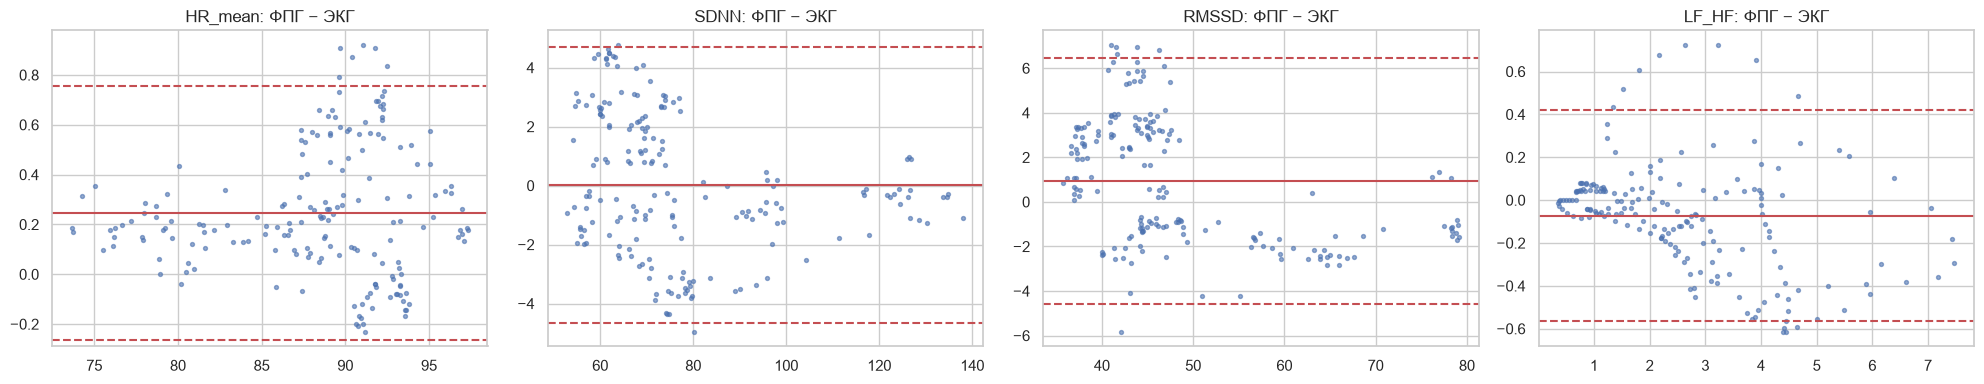

In [6]:
e, p = (pd.read_csv(processed_dir('s14') / f'hrv_{k}.csv') for k in ('ecg', 'ppg'))
m = e.merge(p, on='t', suffixes=('_ecg', '_ppg')); m = m[m.phase_ecg == 'interview']
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, k in zip(axes, ['HR_mean', 'SDNN', 'RMSSD', 'LF_HF']):
    a, b = m[f'{k}_ecg'], m[f'{k}_ppg']
    diff = b - a
    ax.scatter((a + b) / 2, diff, s=8, alpha=.6)
    for v, st in ((0, '-'), (1.96, '--'), (-1.96, '--')):
        ax.axhline(diff.mean() + v * diff.std(), color='C3', ls=st)
    ax.set_title(f'{k}: ФПГ − ЭКГ')
plt.tight_layout()

{'ppg_valid_frac': 0.9799296258415131, 'n_pulses': 1474, 'pat_median_ms': 289.9999999999636, 'riiv_vs_belt_rate_mae': 8.272058823529411, 'airflow_vs_belt_rate_mae': 5.127450980392157, 'oximeter_hr_vs_ecg_mae': 4.907834121537068, 'spo2_median': 98.0}


Text(0, 0.5, 'PAT, мс')

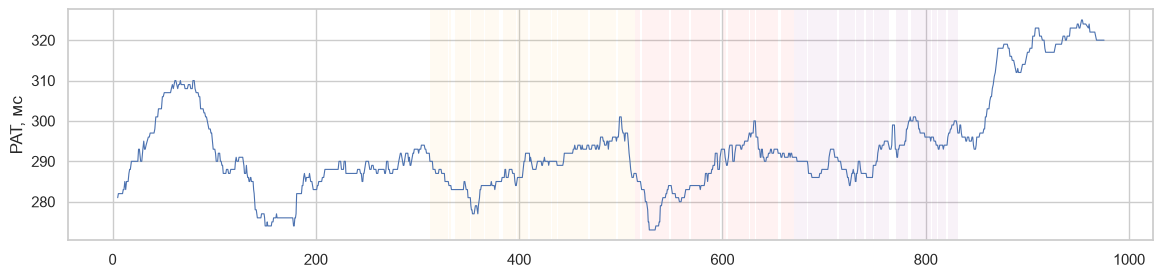

In [7]:
print(load('s14', 'bio_summary.json')['ppg'])
pat = pd.read_csv(processed_dir('s14') / 'pat.csv')
pat = pat[(pat.t_video > 0) & (pat.t_video < sync.loc['s14', 'video_duration'])]
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(pat.t_video, 1000 * pat.pat.rolling(15, center=True).median(), lw=.8)
topics(ax, 's14')
ax.set_ylabel('PAT, мс')

## 4. rPPG против ЭКГ

In [8]:
ev = pd.concat([pd.read_csv(processed_dir(s) / 'rppg_eval.csv').assign(sid=s) for s in sessions()])
ev[ev.reference == 'ECG'].pivot_table(index='sid', columns='method', values='MAE').round(1)

method,CHROM,GREEN,OMIT,POS,contact_PPG
sid,,,,,
s01,10.5,45.8,16.9,8.5,NaN
s02,9.1,43.1,8.9,9.5,NaN
s04,16.9,35.3,29.8,18.0,NaN
s05,11.2,13.0,19.1,15.2,NaN
s06,9.9,31.7,11.4,9.6,NaN
s07,2.4,31.0,1.9,1.9,NaN
s08,3.2,19.6,3.0,2.9,NaN
s09,5.9,11.1,7.7,6.0,NaN
s10,3.0,12.7,3.4,2.9,NaN


In [9]:
ev[ev.reference == 'ECG'].groupby('method')[['MAE', 'within5', 'r']].median().round(2)

,MAE,within5,r
method,,,
CHROM,7.49,0.51,0.55
GREEN,25.33,0.13,-0.12
OMIT,8.32,0.46,0.49
POS,7.22,0.51,0.60
contact_PPG,0.70,0.97,0.99


### Есть ли пульс в видео: усреднение, синхронное с R-зубцами, против случайных моментов

In [10]:
from lie_detector.video import rppg as R
rng, rows, fs = np.random.default_rng(0), [], 25.0
for sid in sessions():
    f = np.load(processed_dir(sid) / 'face_rgb.npz')
    rp = np.load(processed_dir(sid) / 'bio.npz')['rpeaks_s'] - load(sid, 'sync.json')['offset']
    x = R.bandpass(R.pos(R.fill_gaps(R.combine_rois(f['rgb'], f['counts'])), fs), fs, .7, 4)
    x /= x.std()
    def avg(beats):
        idx = np.round(beats * fs).astype(int)
        idx = idx[(idx > 8) & (idx < len(x) - 25)]
        return np.stack([x[i - 8:i + 25] for i in idx]).mean(0)
    obs = avg(rp)
    null = np.array([np.ptp(avg(np.sort(rng.uniform(1, len(x) / fs - 2, len(rp))))) for _ in range(100)])
    rows.append({'sid': sid, 'p2p': np.ptp(obs), 'null_95': np.percentile(null, 95), 'p': (1 + np.sum(null >= np.ptp(obs))) / 101})
pd.DataFrame(rows).set_index('sid').round(3)

,p2p,null_95,p
sid,,,
s01,1.244,0.116,0.01
s02,1.401,0.123,0.01
s04,0.906,0.131,0.01
s05,0.299,0.145,0.01
s06,1.048,0.115,0.01
s07,1.503,0.123,0.01
s08,1.846,0.136,0.01
s09,0.257,0.125,0.01
s10,1.574,0.157,0.01


In [11]:
rr = pd.concat([pd.read_csv(processed_dir(s) / 'resp_rate.csv') for s in sessions()])
rr = rr[rr.phase == 'interview']
print('пояс vs EDR: MAE %.1f вд/мин, r=%.2f' % ((rr.rate_belt - rr.rate_edr).abs().mean(), rr[['rate_belt', 'rate_edr']].corr().iloc[0, 1]))

пояс vs EDR: MAE 5.4 вд/мин, r=0.20


## 5. Сценарий против самоотчёта: доля ответов, отмеченных как ложь

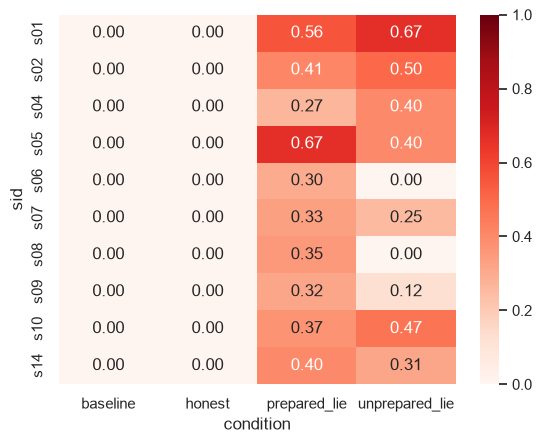

In [12]:
piv = pd.read_csv(OUT / 'label_agreement.csv').pivot_table(index='sid', columns='condition', values='share_self_lie')
sns.heatmap(piv, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1);

## 6. Маркеры лжи (самоотчёт)

Нормирование признаков проводилось для каждого человека индивидуально на основе его ответов, полученных во вступлении.

In [13]:
st = pd.read_csv(OUT / 'stats_self.csv')
st.head(15)[['feature', 'median_diff', 'effect_rb', 'wilcoxon_p', 'wilcoxon_q', 'n_subjects']].round(3)

,feature,median_diff,effect_rb,wilcoxon_p,wilcoxon_q,n_subjects
0,eg_loudness_sma3_stddevRisingSlope,-0.571,-1.000,0.002,0.143,10.0
1,eg_slopeV500-1500_sma3nz_stddevNorm,-0.442,-1.000,0.002,0.143,10.0
2,eg_mfcc3V_sma3nz_stddevNorm,-0.574,-0.964,0.004,0.143,10.0
3,eg_loudness_sma3_meanFallingSlope,-0.666,-0.964,0.004,0.143,10.0
4,eg_StddevUnvoicedSegmentLength,0.296,0.927,0.006,0.143,10.0
5,eg_alphaRatioV_sma3nz_stddevNorm,0.514,0.927,0.006,0.143,10.0
6,latency,0.964,0.855,0.014,0.250,10.0
7,anomaly_norm,0.297,0.855,0.014,0.250,10.0
8,eg_mfcc2_sma3_stddevNorm,1.019,0.818,0.020,0.259,10.0
9,f0_median,-0.788,-0.818,0.020,0.259,10.0


In [14]:
pd.read_csv(OUT / 'confirmatory.csv').round(3)

,feature,expected,median_diff,effect_rb,wilcoxon_p,as_expected,q
0,latency,+,0.964,0.855,0.014,True,0.068
1,pause_ratio,+,0.040,0.091,0.846,True,0.846
2,syll_rate,-,-1.068,-0.382,0.322,True,0.645
3,f0_mean,+,-0.130,-0.309,0.432,False,0.719
4,anomaly_norm,+,0.297,0.855,0.014,True,0.068
5,hr_delta,+,0.053,-0.200,0.625,True,0.846
6,rmssd_local,-,0.071,0.127,0.770,False,0.846
7,resp_amp_ratio,-,0.263,0.564,0.131,False,0.410
8,kin_head_nod_power,-,-0.249,-0.556,0.164,True,0.410
9,kin_rhand_speed_mean,-,-0.001,0.164,0.695,True,0.846


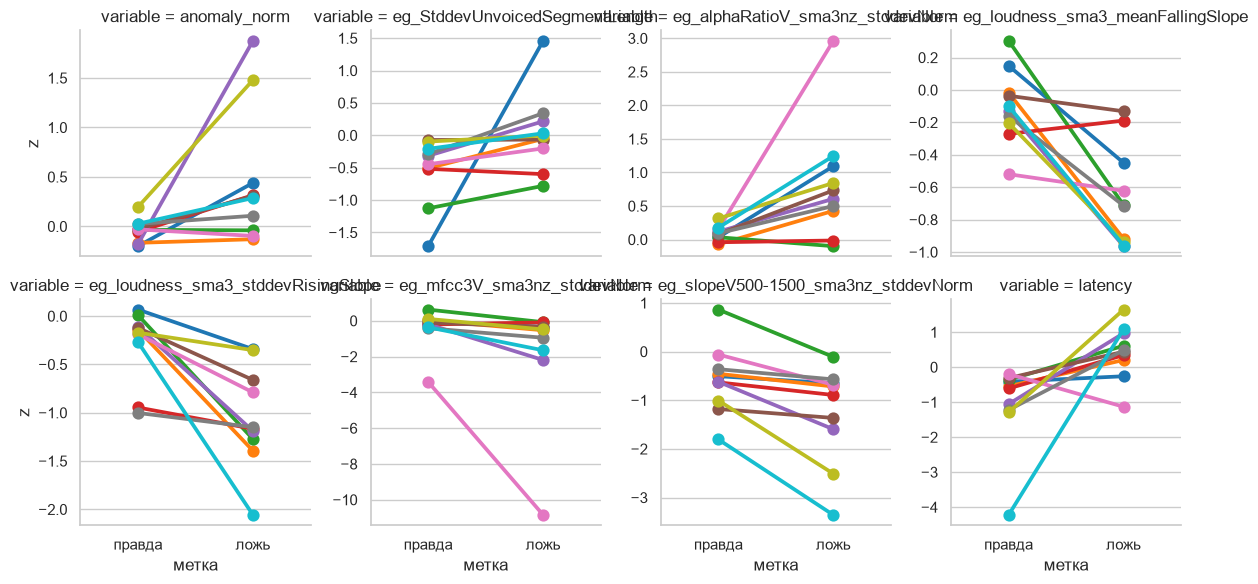

In [15]:
from lie_detector.analysis.dataset import feature_columns
from lie_detector.analysis.stats import preprocess_features
norm = preprocess_features(df, feature_columns(df[df.in_study]))
sel = norm[norm.y_self.notna() & norm.in_study]
top = st.dropna(subset=['wilcoxon_p']).head(8).feature.tolist()
subj = sel.melt(id_vars=['sid', 'y_self'], value_vars=top).groupby(['sid', 'y_self', 'variable']).value.median().reset_index()
subj['метка'] = subj.y_self.map({0: 'правда', 1: 'ложь'})
sns.catplot(subj, x='метка', y='value', col='variable', col_wrap=4, kind='point', hue='sid', legend=False,
            order=['правда', 'ложь'], sharey=False, height=3, palette='tab10').set_ylabels('z');

## 7. Темперамент

In [16]:
df.drop_duplicates('sid').set_index('sid')[['temperament', 'style_natural', 'style_strength', 'emo_balance']]

,temperament,style_natural,style_strength,emo_balance
sid,,,,
s01,NaN,NaN,NaN,NaN
s02,choleric,Контролирующий/Содействующий,2.06,1.0
s04,NaN,NaN,NaN,NaN
s05,NaN,NaN,NaN,NaN
s06,choleric,Контролирующий,3.95,-5.0
s07,choleric,Контролирующий/Содействующий,2.03,0.0
s08,NaN,NaN,NaN,NaN
s09,choleric,Контролирующий/Содействующий,1.26,0.0
s10,choleric,Контролирующий/Содействующий,3.30,-3.0


In [17]:
mm = pd.read_csv(OUT / 'mixed_models.csv')
mm.sort_values('p_interaction').head(10).round(4)

,feature,moderator,beta_lie,p_lie,beta_interaction,p_interaction,n
32,F1_mean,emo_balance,0.5380,0.0449,-0.6431,0.0000,374
86,eg_mfcc2_sma3_amean,emo_balance,0.4019,0.1854,0.6556,0.0000,374
282,kin_head_nod_freq,emo_balance,0.1140,0.4723,-0.3139,0.0001,278
110,eg_logRelF0-H1-H2_sma3nz_amean,emo_balance,0.6814,0.0591,-0.5477,0.0020,374
247,kin_com_shift_x_norm_mean,style_strength,-4.1989,0.0012,1.6253,0.0021,379
33,F1_mean,style_strength,-0.9023,0.2187,0.8935,0.0034,374
283,kin_head_nod_freq,style_strength,-0.9451,0.0452,0.5912,0.0050,278
222,hr_min_delta,emo_balance,0.1178,0.4763,0.2023,0.0074,402
87,eg_mfcc2_sma3_amean,style_strength,1.8413,0.0260,-0.8982,0.0090,374
223,hr_min_delta,style_strength,0.9260,0.0301,-0.4381,0.0110,402


## 8. Классификация (leave-one-subject-out)

In [18]:
pd.read_csv(OUT / 'models.csv')[['labels', 'model', 'features', 'auc', 'bal_acc', 'auc_per_subject_mean', 'n_answers', 'n_lies', 'perm_p']].round(3)

,labels,model,features,auc,bal_acc,auc_per_subject_mean,n_answers,n_lies,perm_p
0,self,logreg,multimodal,0.499,0.518,0.519,638,118,0.408
1,self,gboost,multimodal,0.635,0.532,0.641,638,118,0.005
2,self,gboost,multimodal+temperament,0.610,0.512,0.608,638,118,NaN
3,self,gboost,speech,0.649,0.560,0.663,638,118,NaN
4,self,gboost,physiology,0.551,0.537,0.540,638,118,NaN
5,self,gboost,kinematics,0.585,0.532,0.578,638,118,NaN
6,scenario,logreg,multimodal,0.515,0.518,0.531,514,338,0.353
7,scenario,gboost,multimodal,0.605,0.577,0.621,514,338,0.005
8,scenario,gboost,multimodal+temperament,0.592,0.558,0.605,514,338,NaN
9,scenario,gboost,speech,0.558,0.544,0.569,514,338,NaN


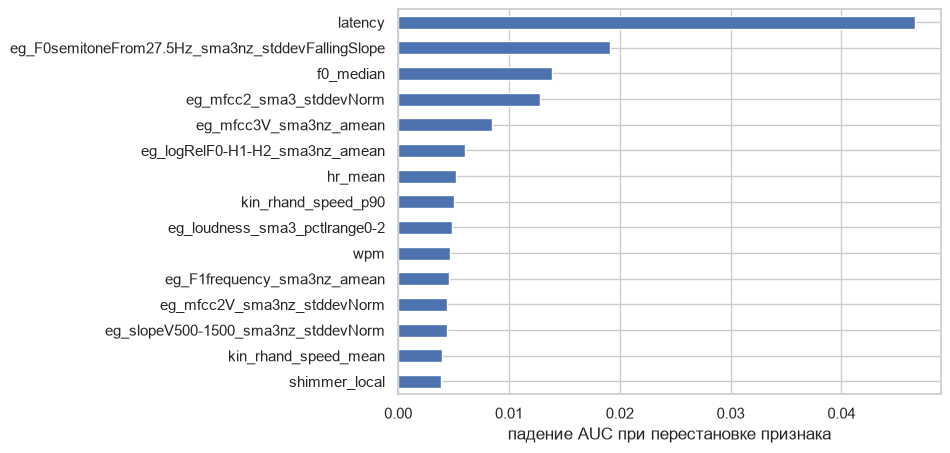

In [19]:
pd.read_csv(OUT / 'importance.csv', index_col=0).auc_drop.head(15)[::-1].plot.barh(figsize=(7, 5))
plt.xlabel('падение AUC при перестановке признака');